In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from torchvision.utils import make_grid
import torch.nn.functional as F

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score
import seaborn as sns

import warnings
# filter warnings
warnings.filterwarnings('ignore')

from tqdm import tqdm

## EDA

In [2]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USER')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

!kaggle datasets download -d puneet6060/intel-image-classification

Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:04<00:00, 81.0MB/s]



In [3]:
!unzip -o intel-image-classification.zip

Показано результат, скорочений до останніх рядків (5000).
  inflating: seg_train/seg_train/mountain/7506.jpg  
  inflating: seg_train/seg_train/mountain/7537.jpg  
  inflating: seg_train/seg_train/mountain/7539.jpg  
  inflating: seg_train/seg_train/mountain/7551.jpg  
  inflating: seg_train/seg_train/mountain/7560.jpg  
  inflating: seg_train/seg_train/mountain/7565.jpg  
  inflating: seg_train/seg_train/mountain/7578.jpg  
  inflating: seg_train/seg_train/mountain/7581.jpg  
  inflating: seg_train/seg_train/mountain/7586.jpg  
  inflating: seg_train/seg_train/mountain/7647.jpg  
  inflating: seg_train/seg_train/mountain/7652.jpg  
  inflating: seg_train/seg_train/mountain/7654.jpg  
  inflating: seg_train/seg_train/mountain/7662.jpg  
  inflating: seg_train/seg_train/mountain/767.jpg  
  inflating: seg_train/seg_train/mountain/7672.jpg  
  inflating: seg_train/seg_train/mountain/7679.jpg  
  inflating: seg_train/seg_train/mountain/7681.jpg  
  inflating: seg_train/seg_train/mountain/

In [4]:
train_dir = '/content/seg_train/seg_train'
test_dir = '/content/seg_test/seg_test'

In [5]:
transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [6]:
train_data = datasets.ImageFolder(train_dir, transform=transform)
test_data = datasets.ImageFolder(test_dir, transform=transform)

In [7]:
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_dataset, val_dataset = random_split(train_data, [train_size, val_size])

In [8]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

In [9]:
print(f"Кількість класів: {len(train_data.classes)}")
print(f"Класи: {train_data.classes}")
print(f"Розмір тренувального набору: {len(train_dataset)}")
print(f"Розмір валідаційного набору: {len(val_dataset)}")
print(f"Розмір тестового набору: {len(test_data)}")

Кількість класів: 6
Класи: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Розмір тренувального набору: 11227
Розмір валідаційного набору: 2807
Розмір тестового набору: 3000


## Modeling, Transfer Learning

## ResNet18

In [10]:
# Завантаження моделі ResNet18 з попередньо натренованими вагами
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Заморожування параметрів моделі (щоб не оновлювалися під час навчання)
for param in model.parameters():
    param.requires_grad = False

# Заміна останнього повнозв'язного шару (fc) на новий, відповідно до кількості класів
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 6)  # 6 класів у наборі даних

# Перенесення моделі на GPU, якщо він доступний
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)  # <-- правильно для ResNet

num_epochs = 10
best_val_loss = float('inf')
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

In [12]:
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in tqdm(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Валідація
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = correct / total
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f'Epoch {epoch+1}/{num_epochs}:')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}')
    print(f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}')


    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'best_model_18.pth')

100%|██████████| 351/351 [00:23<00:00, 15.21it/s]


Epoch 1/10:
Train Loss: 0.5676, Train Accuracy: 0.8068
Val Loss: 0.3855, Val Accuracy: 0.8653


100%|██████████| 351/351 [00:22<00:00, 15.38it/s]


Epoch 2/10:
Train Loss: 0.3616, Train Accuracy: 0.8750
Val Loss: 0.3236, Val Accuracy: 0.8824


100%|██████████| 351/351 [00:19<00:00, 17.64it/s]


Epoch 3/10:
Train Loss: 0.3333, Train Accuracy: 0.8807
Val Loss: 0.3298, Val Accuracy: 0.8807


... (10 outputs left out)

100%|██████████| 351/351 [00:20<00:00, 17.43it/s]


Epoch 9/10:
Train Loss: 0.2933, Train Accuracy: 0.8936
Val Loss: 0.3119, Val Accuracy: 0.8921


100%|██████████| 351/351 [00:20<00:00, 17.48it/s]


Epoch 10/10:
Train Loss: 0.2906, Train Accuracy: 0.8931
Val Loss: 0.3218, Val Accuracy: 0.8867


In [13]:
def plot_training_metrics(train_losses, train_accuracies, val_losses, val_accuracies):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 5))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, 'b-', label='Training Loss')
    plt.plot(epochs, val_losses, 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accuracies, 'b-', label='Training Accuracy')
    plt.plot(epochs, val_accuracies, 'r-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

In [14]:
model.load_state_dict(torch.load('best_model_18.pth'))
model.eval()

correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

Test Accuracy: 0.8943
F1 Score: 0.8933


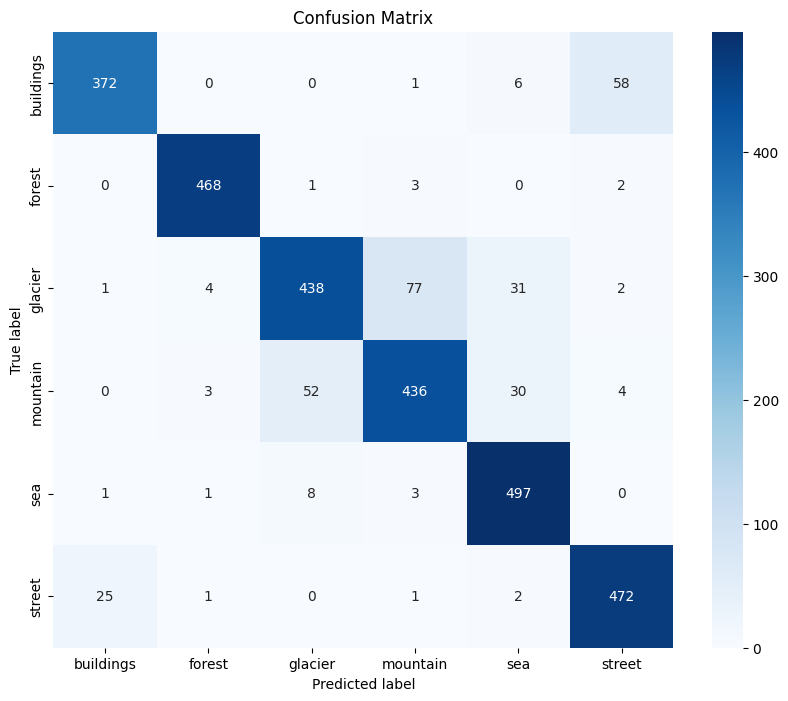

In [15]:
class_names = train_data.classes

# Обчислення точності та F1
test_accuracy = correct / total
f1 = f1_score(all_labels, all_preds, average='weighted')

print(f'Test Accuracy: {test_accuracy:.4f}')
print(f'F1 Score: {f1:.4f}')

# Створення матриці помилок
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

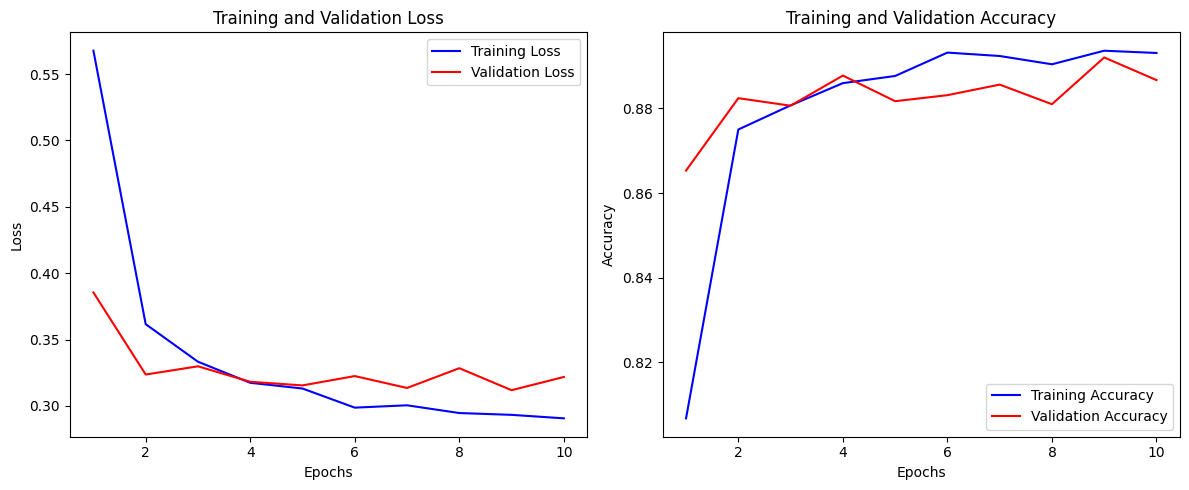

In [16]:
plot_training_metrics(train_losses, train_accuracies, val_losses, val_accuracies)

## ResNet50

In [17]:
# Завантаження моделі ResNet50 з попередньо натренованими вагами
model2 = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Заморожування параметрів моделі (щоб не оновлювалися під час навчання)
for param in model2.parameters():
    param.requires_grad = False

# Заміна останнього повнозв'язного шару (fc) на новий, відповідно до кількості класів
num_ftrs = model2.fc.in_features
model2.fc = nn.Linear(num_ftrs, 6)  # 6 класів у наборі даних

# Перенесення моделі на GPU, якщо він доступний
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model2 = model2.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 198MB/s]


In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model2.fc.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

num_epochs = 15
best_val_loss_50 = float('inf')
train_losses_50 = []
train_accuracies_50 = []
val_losses_50 = []
val_accuracies_50 = []

In [24]:
for epoch in range(num_epochs):
    model2.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in tqdm(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model2(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total

    train_losses_50.append(train_loss)
    train_accuracies_50.append(train_accuracy)

    # Валідація
    model2.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model2(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = correct / total

    val_losses_50.append(val_loss)
    val_accuracies_50.append(val_accuracy)

    print(f'Epoch {epoch+1}/{num_epochs}:')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}')
    print(f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}')

    if val_loss < best_val_loss_50:
        best_val_loss_50 = val_loss
        torch.save(model2.state_dict(), 'best_model_50.pth')

100%|██████████| 351/351 [00:29<00:00, 12.10it/s]


Epoch 1/15:
Train Loss: 1.1419, Train Accuracy: 0.7334
Val Loss: 0.7821, Val Accuracy: 0.8611


100%|██████████| 351/351 [00:29<00:00, 11.92it/s]


Epoch 2/15:
Train Loss: 0.6567, Train Accuracy: 0.8547
Val Loss: 0.5562, Val Accuracy: 0.8685


100%|██████████| 351/351 [00:29<00:00, 12.06it/s]


Epoch 3/15:
Train Loss: 0.5058, Train Accuracy: 0.8722
Val Loss: 0.4680, Val Accuracy: 0.8728


... (20 outputs left out)

100%|██████████| 351/351 [00:30<00:00, 11.61it/s]


Epoch 14/15:
Train Loss: 0.2811, Train Accuracy: 0.9073
Val Loss: 0.3026, Val Accuracy: 0.8967


100%|██████████| 351/351 [00:30<00:00, 11.65it/s]


Epoch 15/15:
Train Loss: 0.2791, Train Accuracy: 0.9056
Val Loss: 0.2956, Val Accuracy: 0.9002


In [25]:
model2.load_state_dict(torch.load('best_model_50.pth'))
model2.eval()

correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model2(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

Test Accuracy: 0.9003
F1 Score: 0.8998


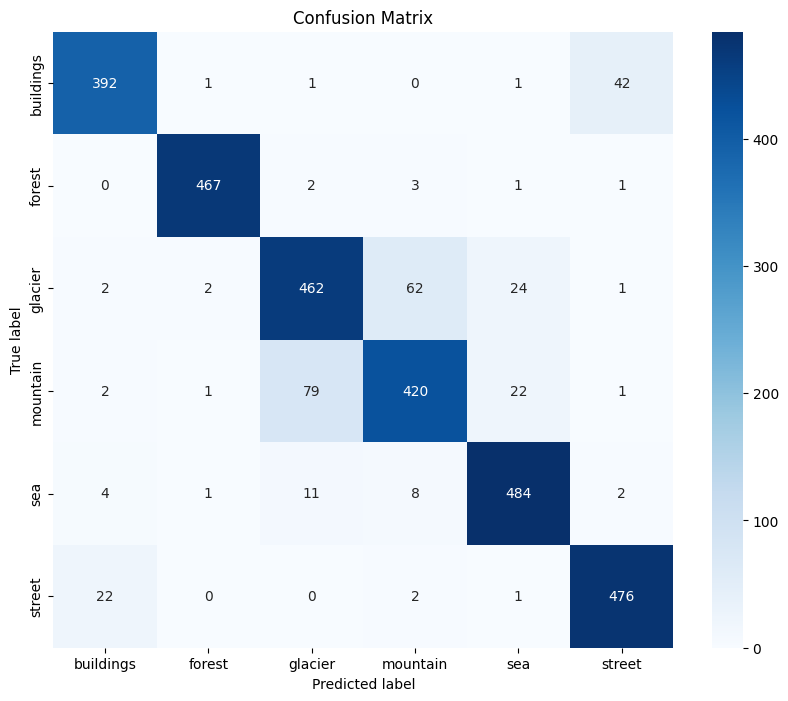

In [26]:
class_names = train_data.classes

# Обчислення точності та F1
test_accuracy = correct / total
f1 = f1_score(all_labels, all_preds, average='weighted')

print(f'Test Accuracy: {test_accuracy:.4f}')
print(f'F1 Score: {f1:.4f}')

# Створення матриці помилок
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

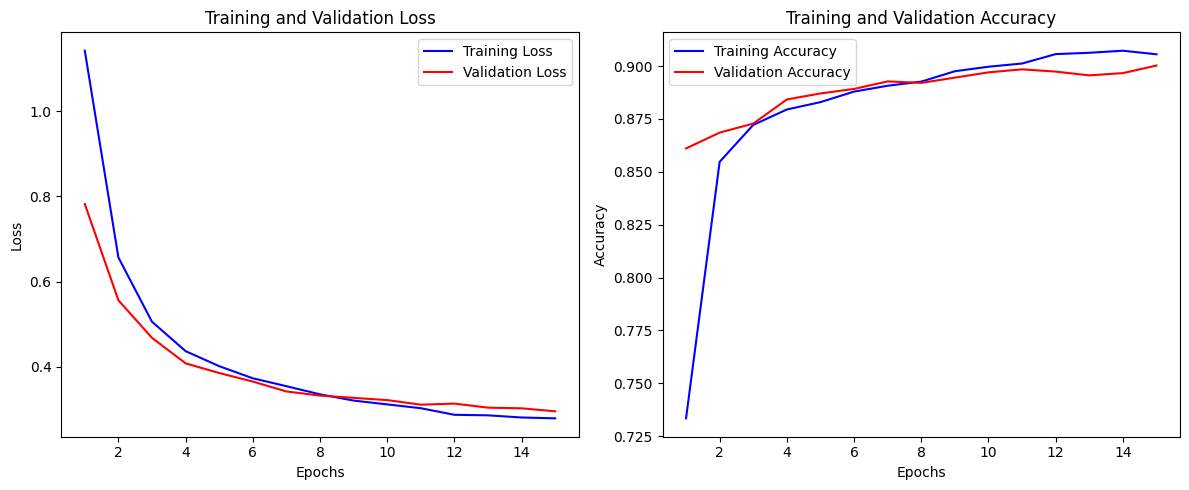

In [30]:
plot_training_metrics(train_losses_50, train_accuracies_50, val_losses_50, val_accuracies_50)

ВИСНОВКИ

У ході виконання роботи було розроблено моделі глибокого навчання для класифікації зображень з набору даних Intel Image Classification. Було обрано підхід трансферного навчання: попередньо натреновані моделі ResNet18 та ResNet50.


Перший експеримент ResNet18 за 10 епох показав досить високі результати:

Train Loss: 0.2906, Train Accuracy: 0.8931
Val Loss: 0.3218, Val Accuracy: 0.8867, F1 Score: 0.8933


Для другого експерименту для ResNet50 було збільшено кількість епох до 15 та здійснено налаштування гіперпараметрів оптимізатора:

Train Loss: 0.2791, Train Accuracy: 0.9056
Val Loss: 0.2956, Val Accuracy: 0.9002, F1 Score: 0.8998

Бачимо, що обидві моделі стикнулися зі складністю в розпізнаванні одних і тих самих класів.

Загалом ResNet50 продемонструвала кращу загальну продуктивність. Крім того в неї більш стабільне поступове зниження validation loss до 15-ї епохи, що свідчить про продовження навчання. Недоліком ResNet50 є більший час навчання - близько 30 секунд на епоху проти приблизно 20 секунд у ResNet18.

Таким чином, для максимальної точності доцільно обрати ResNet50, тоді як ResNet18 є швидшою та менш обчислювально затратною альтернативою з лише незначним зниженням якості.
